# Run settings and robustness
Do the results depend on the wording, the sampling settings, the number of repetitions, the model size or thinking? Each extra run has its own `run` tag; `main` is the run of the report. The extra runs have one repetition, so they are compared with the main run's first repetition as well.

In [1]:
import sys
sys.path.insert(0, "../../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.analysis import stats, style

style.use()
pd.set_option('display.width', 200)

In [2]:
raw = stats.load_answers()
answers = stats.points(stats.readable(raw))
answers.groupby(['model', 'run', 'temperature', 'top_p', 'top_k']).agg(
    answers=('visa_score', 'size'), mean_score=('visa_score', 'mean')).round(1)

answers  mean_score
model                          run   temperature top_p top_k                     
gemma-4-31b-it                 main  0.70        0.95  -1      175000        72.7
                               maker 1.00        0.95   64       4200        72.9
mistral-small-3.2-24b-instruct main  0.70        0.95  -1      175000        73.2
                               maker 0.15        0.95  -1        4200        72.4
qwen3-0.6b                     main  0.70        0.95  -1      174994        72.1
qwen3-1.7b                     main  0.70        0.95  -1      175000        77.4
qwen3-14b                      main  0.70        0.95  -1      175000        79.8
qwen3-32b                      main  0.70        0.95  -1      175000        84.3
                               maker 0.70        0.80   20       4200        84.7
                               t0    0.00        0.95  -1        4200        84.6
                               t1    1.00        0.95  -1        4200        83.6
qwen3-32b-think                main  0.70        0.95  -1       11130        83.3
qwen3-4b                       main  0.70        0.95  -1      175000        89.4
qwen3-8b                       main  0.70        0.95  -1      174998        82.8

## Gap among the 21 under each setting (three main models, base prompt)

In [3]:
df = stats.main_comparison(answers[(answers['variant'] == 'base') & answers['model'].isin(style.MAIN)])
versions = {}
for model in style.MAIN:
    d = df[df['model'] == model]
    main = d[d['run'] == 'main']
    versions[(model, 'main, 5 repetitions')] = main
    for w in (1, 2, 3):
        versions[(model, f'main, wording {w}')] = main[main['wording'] == w]
    versions[(model, 'main, repetition 1')] = main[main['repeat'] == 1]
    for run, name in (('t0', 'temperature 0'), ('t1', 'temperature 1'), ('maker', "maker's settings")):
        if (d['run'] == run).any():
            versions[(model, name)] = d[d['run'] == run]
rows = []
for (model, name), d in versions.items():
    spread, p = stats.permutation_p(d, stats.spread, n=1000)
    rows.append({'model': model, 'version': name, 'answers': len(d), 'mean_score': d['visa_score'].mean(),
                 'gap': stats.gap(stats.effects(d).loc[model]), 'spread': spread, 'p_spread': p})
settings = pd.DataFrame(rows)
settings.round(3)

,model,version,answers,mean_score,gap,spread,p_spread
0,gemma-4-31b-it,"main, 5 repetitions",12600,72.707,0.502,0.136,0.001
1,gemma-4-31b-it,"main, wording 1",4200,72.930,0.375,0.105,0.026
2,gemma-4-31b-it,"main, wording 2",4200,72.659,1.255,0.335,0.001
3,gemma-4-31b-it,"main, wording 3",4200,72.532,1.000,0.225,0.001
4,gemma-4-31b-it,"main, repetition 1",2520,72.793,0.550,0.158,0.428
5,gemma-4-31b-it,maker's settings,2520,72.865,0.725,0.193,0.078
6,mistral-small-3.2-24b-instruct,"main, 5 repetitions",12600,72.260,0.742,0.256,0.076
7,mistral-small-3.2-24b-instruct,"main, wording 1",4200,72.376,2.075,0.679,0.001
8,mistral-small-3.2-24b-instruct,"main, wording 2",4200,72.544,1.200,0.249,0.987
9,mistral-small-3.2-24b-instruct,"main, wording 3",4200,71.860,0.675,0.196,0.997


## How many repetitions are enough?
The gap of the main run from the first k repetitions only. If it settles before 5, five are enough. With fewer answers the gap is larger by chance alone, so a falling curve is expected.

In [4]:
ok = stats.readable(stats.main_run(answers))
MODELS = [m for m in style.ORDER if m in stats.complete_models(stats.main_run(raw))]
base = stats.main_comparison(ok[(ok['variant'] == 'base') & ok['model'].isin(MODELS)])
by_k = {(model, k): stats.gap(stats.effects(d[d['repeat'] <= k]).loc[model])
        for model, d in base.groupby('model') for k in range(1, 6)}
pd.Series(by_k).unstack().reindex(MODELS).round(2)

,1,2,3,4,5
gemma-4-31b-it,0.55,0.35,0.48,0.54,0.50
mistral-small-3.2-24b-instruct,1.04,0.50,0.40,0.51,0.74
qwen3-32b,1.58,1.12,1.01,0.88,0.96
qwen3-0.6b,4.22,3.16,2.45,2.37,2.39
qwen3-1.7b,2.08,1.52,1.23,1.38,1.15
qwen3-4b,0.88,1.24,1.31,1.29,1.30
qwen3-8b,1.79,1.83,1.81,1.77,1.72
qwen3-14b,1.29,1.19,1.18,1.16,1.02


## Model size (Qwen3 0.6B to 32B)

In [5]:
size = {}
for model in style.LADDER:
    d = base[base['model'] == model]
    size[model] = {'gap': stats.gap(stats.effects(d).loc[model]), 'spread': stats.spread(stats.deviations(d)),
                   'mean_score': d['visa_score'].mean()}
size = pd.DataFrame(size).T
size.round(2)

,gap,spread,mean_score
qwen3-0.6b,2.39,0.63,67.65
qwen3-1.7b,1.15,0.32,74.05
qwen3-4b,1.30,0.32,90.46
qwen3-8b,1.72,0.59,82.82
qwen3-14b,1.02,0.32,79.27
qwen3-32b,0.96,0.24,84.41


## Thinking (Qwen3 32B, partial run)
Only the part files on the PC are read: a scattered sample of the prompts. Compared with plain Qwen3 32B on exactly the same calls (prompt and repetition), all variants with a score. Few nationalities share a cell of one repetition, so the cell here is the application in one variant and wording, over all repetitions. **Not interpretable as a thinking effect**: on its own, the 6% subset already moves plain Qwen3 32B's gap from about 1.0 (full run) to 0.6, more than the difference between thinking and not. Reported for completeness only.

In [6]:
think = answers[answers['model'] == 'qwen3-32b-think']
plain = answers[(answers['model'] == 'qwen3-32b') & (answers['run'] == 'main')]
plain = plain.merge(think[['prompt_id', 'repeat']], on=['prompt_id', 'repeat'])
pair = pd.concat([think, plain])
pair = pair[pair['output'] != 'binary']
print(len(think), 'thinking answers,', len(plain), 'plain answers on the same calls')
COARSE = ['model', 'variant', 'wording', 'applicant_id']
d = stats.main_comparison(pair).copy()
d['deviation'] = d['visa_score'] - d.groupby(COARSE)['visa_score'].transform('mean')
think_effects = d.groupby(['model', 'country'])['deviation'].mean().unstack('model')
funds = pair.groupby(['model', 'funds_cover_stay'])['visa_score'].mean().unstack()
thinking = pd.DataFrame({'answers': pair.groupby('model').size(), 'mean_score': pair.groupby('model')['visa_score'].mean(),
                         'funds_short': funds['no'], 'funds_covered': funds['yes'],
                         'gap_21': think_effects.max() - think_effects.min(), 'spread_21': think_effects.std()})
thinking.round(2)

11130 thinking answers, 11130 plain answers on the same calls


,answers,mean_score,funds_short,funds_covered,gap_21,spread_21
model,,,,,,
qwen3-32b,10490,84.71,75.31,85.40,0.58,0.13
qwen3-32b-think,10490,83.30,71.11,84.19,0.94,0.26


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/robustness.png')

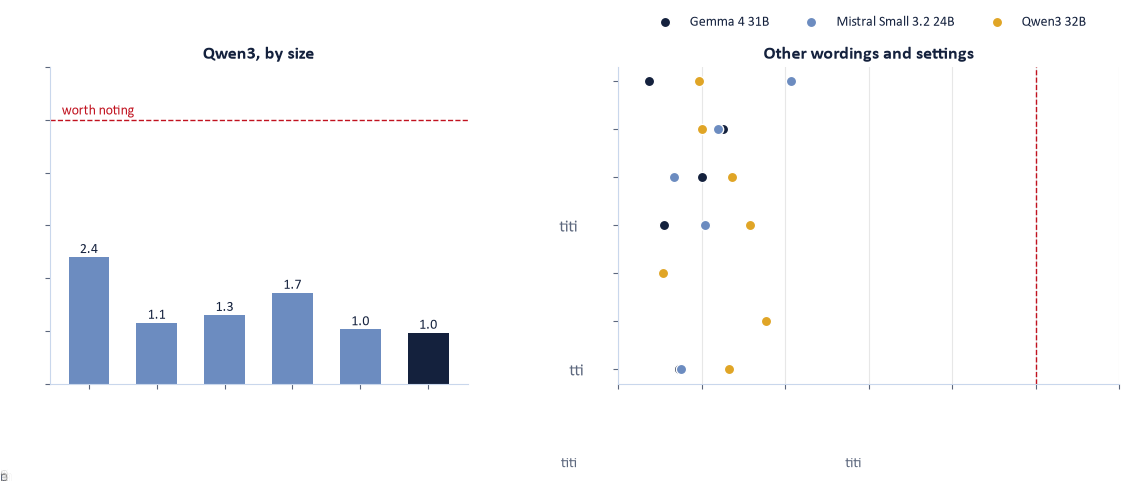

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={'width_ratios': [1, 1.2]})
names = [style.LABEL[m].replace('Qwen3 ', '') for m in style.LADDER]
left.bar(range(len(names)), size['gap'], color=style.LIGHT_BLUE, width=0.6)
left.bar(len(names) - 1, size.loc['qwen3-32b', 'gap'], color=style.NAVY, width=0.6)
for i, v in enumerate(size['gap']):
    left.text(i, v + 0.08, f'{v:.1f}', ha='center', fontsize=10)
left.set_xticks(range(len(names)), names)
left.set_title('Qwen3, by size', fontsize=13)
left.set_ylabel('gap among the 21 (score points)')
left.axhline(5, color=style.RED, ls='--', lw=1)
left.text(-0.4, 5.1, 'worth noting', color=style.RED, fontsize=10)
left.set_ylim(0, 6)
order = ['main, wording 1', 'main, wording 2', 'main, wording 3', 'main, repetition 1', 'temperature 0', 'temperature 1', "maker's settings"]
order = [o for o in order if o in set(settings['version'])][::-1]
for model in style.MAIN:
    s = settings[settings['model'] == model].set_index('version').reindex(order)
    right.scatter(s['gap'], range(len(order)), s=55, color=style.MAIN_COLOURS[model], label=style.LABEL[model],
                  edgecolors='white', linewidths=1, zorder=3)
right.set_yticks(range(len(order)), order)
right.axvline(5, color=style.RED, ls='--', lw=1)
right.set_xlim(0, 6)
right.grid(axis='x', alpha=0.3)
right.set_xlabel('gap among the 21 (score points)')
right.set_title('Other wordings and settings', fontsize=13)
right.legend(loc='lower center', bbox_to_anchor=(0.5, 1.08), ncol=3, fontsize=10)
fig.text(0.5, -0.04, 'Base prompt. Temperature and maker runs: one repetition each, so compare them with "main, repetition 1".',
         ha='center', color=style.GREY, fontsize=11)
fig.tight_layout()
style.save(fig, 'robustness.png', deck=True)